# Expectation–Maximization (EM) Algorithm Model

This notebook implements EM directly using NumPy and SciPy.


## 1. Statistical model and the estimation problem

We observe $X=(x_1,\ldots,x_n)$ and assume independent observations from a mixture of $K$ univariate Gaussian distributions:

$$
 p(x_i\mid\theta)=\sum_{k=1}^{K}\pi_k\,\phi(x_i;\mu_k,\sigma_k^2),\qquad
 \phi(x;\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right].
$$

The parameters are $\theta=\{(\pi_k,\mu_k,\sigma_k^2)\}_{k=1}^{K}$, subject to $\pi_k\geq0$, $\sum_k\pi_k=1$, and $\sigma_k^2>0$. Here $\pi$ in $\sqrt{2\pi}$ is the mathematical constant, while $\pi_k$ denotes a mixture weight.

The observed-data likelihood and log-likelihood are

$$
L(\theta;X)=\prod_{i=1}^{n}\left[\sum_{k=1}^{K}\pi_k\phi(x_i;\mu_k,\sigma_k^2)\right],
\qquad
\ell(\theta)=\sum_{i=1}^{n}\log\left[\sum_{k=1}^{K}\pi_k\phi(x_i;\mu_k,\sigma_k^2)\right].
$$

The logarithm of a sum makes the first-order conditions difficult to solve directly. EM introduces unobserved component labels to obtain a tractable surrogate objective.

## 2. Latent component labels and complete-data likelihood

Let $Z_i\in\{1,\ldots,K\}$ denote the unknown component generating $x_i$, and define $z_{ik}=\mathbf 1\{Z_i=k\}$. Then $\sum_k z_{ik}=1$ and

$$
P(Z_i=k)=\pi_k,\qquad p(x_i\mid Z_i=k,\theta)=\phi(x_i;\mu_k,\sigma_k^2).
$$

If the labels were known, the joint density and complete-data log-likelihood would be

$$
p(X,Z\mid\theta)=\prod_{i=1}^n\prod_{k=1}^K\left[\pi_k\phi(x_i;\mu_k,\sigma_k^2)\right]^{z_{ik}},
$$

$$
\ell_c(\theta;X,Z)=\sum_{i=1}^n\sum_{k=1}^K z_{ik}\left[\log\pi_k-\frac12\log(2\pi)-\log\sigma_k-\frac{(x_i-\mu_k)^2}{2\sigma_k^2}\right].
$$

Because $Z$ is unobserved, we replace $z_{ik}$ by its conditional expectation given the data and the *current* parameter estimate.

## 3. Initialization

The input is converted to a one-dimensional numeric array, with $n=\operatorname{len}(X)$. The algorithm starts from $\theta^{(0)}$:

$$
\mu_k^{(0)}\in\{x_1,\ldots,x_n\},\qquad
\sigma_k^{(0)}=\max\{\operatorname{std}(X),10^{-3}\},\qquad
\pi_k^{(0)}=1/K.
$$

The initial means depend on the random seed. Because the mixture likelihood is non-concave, different initializations may lead to different stationary points. Equal initial weights are used as a neutral starting point.

## 4. E-step: posterior responsibilities

At iteration $t$, the E-step computes

$$
\gamma_{ik}^{(t)}=E[z_{ik}\mid X,\theta^{(t)}]=P(Z_i=k\mid x_i,\theta^{(t)}).
$$

Bayes' rule gives

$$
\gamma_{ik}^{(t)}=\frac{\pi_k^{(t)}\phi(x_i;\mu_k^{(t)},(\sigma_k^{(t)})^2)}{\sum_{j=1}^{K}\pi_j^{(t)}\phi(x_i;\mu_j^{(t)},(\sigma_j^{(t)})^2)}.
$$

For every observation, $\sum_{k=1}^{K}\gamma_{ik}^{(t)}=1$. These are posterior probabilities, i.e. soft assignments of each observation to the components.

### Numerical implementation

Define $a_{ik}=\log\pi_k+\log\phi(x_i;\mu_k,\sigma_k^2)$. Then

$$
\log p(x_i\mid\theta)=\operatorname{logsumexp}(a_{i1},\ldots,a_{iK}),\qquad
\gamma_{ik}=\exp\left[a_{ik}-\operatorname{logsumexp}(a_{i1},\ldots,a_{iK})\right].
$$

The `log_prob` array has shape $(n,K)$; `.T` transposes the per-component output into rows of observations. `logsumexp(..., axis=1)` produces one log mixture density per observation. `log_den[:, None]` changes shape $(n,)$ to $(n,1)$ so NumPy broadcasts it across $K$ columns.

Log-space calculations avoid underflow when Gaussian densities are extremely small.

## 5. The EM objective: expected complete-data log-likelihood

The E-step forms the conditional expectation of the complete-data log-likelihood:

$$
Q(\theta\mid\theta^{(t)})=E_{Z\mid X,\theta^{(t)}}[\ell_c(\theta;X,Z)].
$$

Substituting $E[z_{ik}\mid X,\theta^{(t)}]=\gamma_{ik}^{(t)}$ yields

$$
Q(\theta\mid\theta^{(t)})=\sum_{i=1}^{n}\sum_{k=1}^{K}\gamma_{ik}^{(t)}\left[\log\pi_k-\frac12\log(2\pi)-\frac12\log\sigma_k^2-\frac{(x_i-\mu_k)^2}{2\sigma_k^2}\right].
$$

In the M-step, the $\gamma_{ik}^{(t)}$ are held fixed while $Q$ is maximized over the new parameters $\theta$.

## 6. M-step: effective sample sizes and mixture weights

Define the effective size of component $k$:

$$N_k=\sum_{i=1}^{n}\gamma_{ik}^{(t)}.$$

Since $\sum_k\gamma_{ik}^{(t)}=1$, we have $\sum_kN_k=n$. The part of $Q$ involving weights is $\sum_kN_k\log\pi_k$. Maximize it under $\sum_k\pi_k=1$ using a Lagrange multiplier:

$$
\mathcal J(\pi,\lambda)=\sum_{k=1}^{K}N_k\log\pi_k+\lambda\left(\sum_{k=1}^{K}\pi_k-1\right).
$$

For interior weights,

$$
\frac{\partial\mathcal J}{\partial\pi_k}=\frac{N_k}{\pi_k}+\lambda=0
\quad\Rightarrow\quad \pi_k=-\frac{N_k}{\lambda}.
$$

Sum over $k$ and impose the constraint: $1=-n/\lambda$, so $\lambda=-n$. Hence

$$\pi_k^{(t+1)}=\frac{N_k}{n}.$$

The update preserves nonnegative weights and makes them sum to one (up to floating-point error).

## 7. M-step: means

For a fixed component $k$, the mean-dependent part of $Q$ is

$$Q_{\mu_k}=-\frac{1}{2\sigma_k^2}\sum_{i=1}^{n}\gamma_{ik}^{(t)}(x_i-\mu_k)^2.$$

Differentiate with respect to $\mu_k$:

$$
\frac{\partial Q}{\partial\mu_k}=\frac{1}{\sigma_k^2}\sum_i\gamma_{ik}^{(t)}(x_i-\mu_k)=0.
$$

Rearrange:

$$
\sum_i\gamma_{ik}^{(t)}x_i-\mu_k\sum_i\gamma_{ik}^{(t)}=0
\quad\Rightarrow\quad
\mu_k^{(t+1)}=\frac{\sum_i\gamma_{ik}^{(t)}x_i}{N_k}.
$$

The result is a responsibility-weighted mean. In NumPy, `X[:, None]` has shape $(n,1)$ and `gamma * X[:, None]` has shape $(n,K)$. Summing `axis=0` gives the numerator for every component.

## 8. M-step: variances

Write $v_k=\sigma_k^2$. Holding the responsibilities and mean fixed, the variance-dependent part is

$$
Q_{v_k}=-\frac12\sum_{i=1}^{n}\gamma_{ik}^{(t)}\left[\log v_k+\frac{(x_i-\mu_k)^2}{v_k}\right].
$$

Differentiate with respect to $v_k$:

$$
\frac{\partial Q}{\partial v_k}=-\frac12\sum_i\gamma_{ik}^{(t)}\left[\frac1{v_k}-\frac{(x_i-\mu_k)^2}{v_k^2}\right]=0.
$$

Multiplying through by $-2v_k^2$ gives

$$
\sum_i\gamma_{ik}^{(t)}\left[v_k-(x_i-\mu_k)^2\right]=0.
$$

Therefore, using the *updated* mean,

$$
(\sigma_k^2)^{(t+1)}=\frac{\sum_i\gamma_{ik}^{(t)}(x_i-\mu_k^{(t+1)})^2}{N_k}.
$$

The code stores standard deviations, so it takes a square root. Its `np.maximum(variance, 1e-6)` applies a **variance floor** to avoid a zero or nearly zero fitted variance. The floor only changes the update when it is active.

## 9. Observed log-likelihood and stopping criterion

After computing the E-step probabilities at $\theta^{(t)}$, the code evaluates

$$
\ell(\theta^{(t)})=\sum_{i=1}^{n}\log\left[\sum_{k=1}^{K}\pi_k^{(t)}\phi(x_i;\mu_k^{(t)},(\sigma_k^{(t)})^2)\right]
=\sum_{i=1}^{n}\texttt{log\_den}[i].
$$

The notebook stops when two successive evaluated log-likelihoods satisfy

$$|\ell(\theta^{(t)})-\ell(\theta^{(t-1)})|<10^{-6}.$$

This is an absolute likelihood-change criterion; it does not by itself imply that the parameters have converged or that the global optimum has been reached. The test occurs before the next M-step, so the length of `ll` is the number of likelihood evaluations.

In a mathematically exact EM iteration, the observed-data likelihood is nondecreasing. In finite-precision calculations, or when variance floors intervene, small deviations can occur.

## 10. Why EM increases the likelihood: Jensen's inequality and the ELBO

For any distribution $q(Z)$ supported wherever $p(X,Z\mid\theta)$ is positive,

$$
\ell(\theta)=\log\sum_Z q(Z)\frac{p(X,Z\mid\theta)}{q(Z)}
\geq\sum_Z q(Z)\log\frac{p(X,Z\mid\theta)}{q(Z)},
$$

where the inequality follows from the concavity of the logarithm (Jensen's inequality). Define the evidence lower bound

$$
\mathcal F(q,\theta)=E_q[\log p(X,Z\mid\theta)]-E_q[\log q(Z)].
$$

An exact identity is

$$
\ell(\theta)=\mathcal F(q,\theta)+D_{\mathrm{KL}}\big(q(Z)\,\|\,p(Z\mid X,\theta)\big).
$$

The KL divergence is nonnegative, hence $\mathcal F(q,\theta)\leq\ell(\theta)$.

**E-step.** Set $q^{(t)}(Z)=p(Z\mid X,\theta^{(t)})$. The KL term is then zero at $\theta^{(t)}$, so $\mathcal F(q^{(t)},\theta^{(t)})=\ell(\theta^{(t)})$.

**M-step.** Hold $q^{(t)}$ fixed and maximize $\mathcal F(q^{(t)},\theta)$ with respect to $\theta$. Since the entropy $-E_q\log q$ does not depend on $\theta$, this is equivalent to maximizing $Q(\theta\mid\theta^{(t)})$.

Thus, for exact updates,

$$
\ell(\theta^{(t+1)})\geq\mathcal F(q^{(t)},\theta^{(t+1)})\geq\mathcal F(q^{(t)},\theta^{(t)})=\ell(\theta^{(t)}).
$$

This establishes monotonicity of the likelihood, but it does not guarantee a global maximum: Gaussian mixtures have multiple local solutions and an unbounded unconstrained likelihood as a component collapses onto an observation with variance tending to zero.

## 11. Implementation

The function below alternates the posterior-probability calculation (E-step) and weighted parameter updates (M-step).

In [1]:
import numpy as np
from scipy.stats import norm
from scipy.special import logsumexp
import matplotlib.pyplot as plt


# EXPECTATION-MAXIMIZATION (EM) ALGORITHM

def em_gmm(X, K=2, max_iter=1000, tol=1e-6):
    
    # STEP 1: Prepare the observations as a one-dimensional array.
    X = np.asarray(X, dtype=float).ravel()
    n = len(X)

    # STEP 2: Initialize parameters.
    rng = np.random.default_rng(42)
    mu = rng.choice(X, K, replace=False).astype(float)
    sigma = np.full(K, max(np.std(X), 1e-3))
    pi = np.ones(K) / K
    log_likelihood = []

    # STEP 3: Alternate the E-step and M-step.
    for iteration in range(max_iter):
        # E-STEP: log(pi_k * f_k(x_i)) for each observation/component.
        # Shape: (n, K). Logarithms improve numerical stability.
        log_prob = np.array([
            np.log(pi[k]) + norm.logpdf(X, loc=mu[k], scale=sigma[k])
            for k in range(K)
        ]).T

        # log p(x_i | theta) = log(sum_k pi_k * f_k(x_i)).
        log_den = logsumexp(log_prob, axis=1)

        # Responsibilities: gamma_ik = P(Z_i=k | x_i, theta).
        # Every row sums to 1; [:, None] enables broadcasting.
        gamma = np.exp(log_prob - log_den[:, None])

        # STEP 4: Observed-data log-likelihood.
        ll = np.sum(log_den)
        log_likelihood.append(ll)

        # Stop if consecutive log-likelihood evaluations are close.
        # The check is made before the next M-step.
        if iteration > 0 and abs(log_likelihood[-1] - log_likelihood[-2]) < tol:
            break

        # M-STEP: Maximize expected complete-data log-likelihood.
        # STEP 5: Effective component sizes N_k = sum_i gamma_ik.
        Nk = gamma.sum(axis=0)

        # STEP 6: Mixture weights pi_k = N_k / n.
        pi = Nk / n

        # STEP 7: Weighted means mu_k = sum_i(gamma_ik*x_i) / N_k.
        mu = (gamma * X[:, None]).sum(axis=0) / Nk

        # STEP 8: Weighted variances around UPDATED means.
        variance = (gamma * (X[:, None] - mu)**2).sum(axis=0) / Nk

        # Numerical variance floor; sigma stores standard deviations.
        sigma = np.sqrt(np.maximum(variance, 1e-6))

    # STEP 9: Return fitted parameters and convergence history.
    return mu, sigma, pi, log_likelihood


## 12. Simulated example and parameter interpretation

The test data are generated independently from

$$X_1\sim\mathcal N(2,1^2),\quad n_1=600,\qquad X_2\sim\mathcal N(8,1.5^2),\quad n_2=400.$$

After concatenation, the algorithm receives only the observations $X$, not their generating labels. With $K=2$, the target values are approximately

$$\mu=(2,8),\qquad\sigma=(1,1.5),\qquad\pi=(0.6,0.4).$$

Finite-sample estimates will differ from these values. The component labels are interchangeable: swapping components does not change the mixture density. The code sorts the fitted components by estimated mean for readable output.

In [2]:
# Generate synthetic data with two Gaussian components.
rng = np.random.default_rng(123)
X1 = rng.normal(loc=2, scale=1, size=600)     # N(2, 1^2)
X2 = rng.normal(loc=8, scale=1.5, size=400)   # N(8, 1.5^2)
X = np.concatenate([X1, X2])

# Fit the Gaussian mixture using our own EM implementation.
mu, sigma, pi, ll = em_gmm(X, K=2)

# Sort by the estimated means.
order = np.argsort(mu)
mu, sigma, pi = mu[order], sigma[order], pi[order]

print("Estimated means:", mu)
print("Estimated standard deviations:", sigma)
print("Estimated mixture weights:", pi)
print("Final log-likelihood:", ll[-1])
print("Number of likelihood evaluations:", len(ll))


Estimated means: [2.04903211 8.12585108]
Estimated standard deviations: [1.04679193 1.43772656]
Estimated mixture weights: [0.60829961 0.39170039]
Final log-likelihood: -2239.659975058376
Number of likelihood evaluations: 17


## 13. Fitted densities and convergence diagnostics

The density drawn for component $k$ is **weighted** by $\pi_k$:

$$g_k(x)=\pi_k\phi(x;\mu_k,\sigma_k^2),\qquad \widehat f(x)=\sum_{k=1}^{K}g_k(x).$$

Consequently, each dashed component curve has total area $\pi_k$, and the sum of all component curves has total area one. The histogram is normalized with `density=True` so its vertical scale is comparable to the fitted density.

The second plot traces $\ell(\theta^{(t)})$ over successive evaluations. A plateau indicates that the stopping criterion is close to being met.

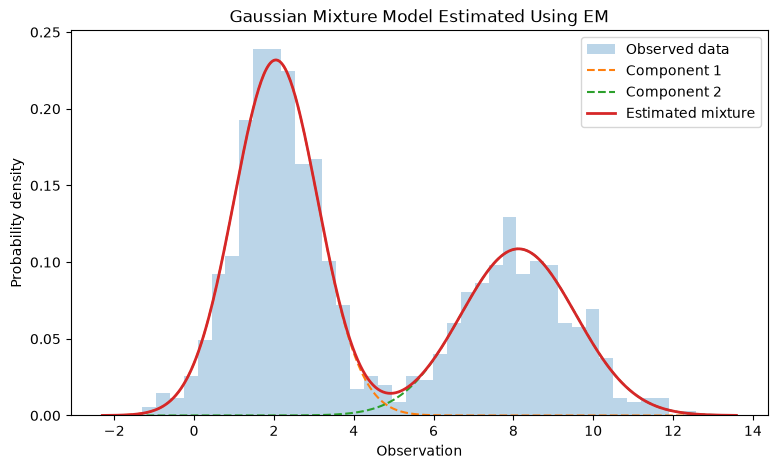

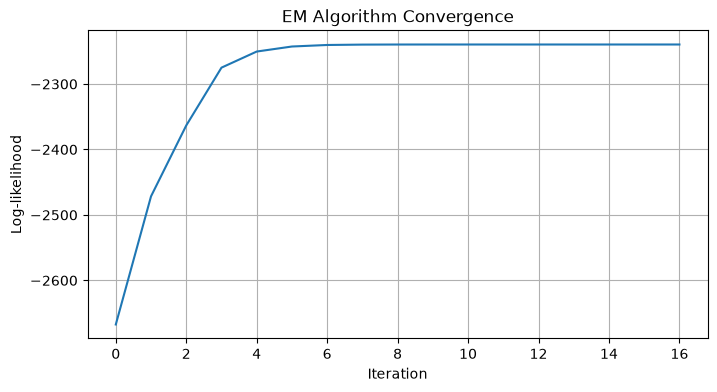

In [3]:
# Plot the observed data, individual weighted components, and fitted mixture.
x_grid = np.linspace(X.min() - 1, X.max() + 1, 500)
mixture_density = np.zeros_like(x_grid)

plt.figure(figsize=(9, 5))
plt.hist(X, bins=40, density=True, alpha=0.3, label="Observed data")
for k in range(len(mu)):
    component_density = pi[k] * norm.pdf(x_grid, loc=mu[k], scale=sigma[k])
    mixture_density += component_density
    plt.plot(x_grid, component_density, "--", label=f"Component {k+1}")
plt.plot(x_grid, mixture_density, linewidth=2, label="Estimated mixture")
plt.xlabel("Observation")
plt.ylabel("Probability density")
plt.title("Gaussian Mixture Model Estimated Using EM")
plt.legend()
plt.show()

# Plot log-likelihood to examine convergence.
plt.figure(figsize=(8, 4))
plt.plot(ll)
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM Algorithm Convergence")
plt.grid(True)
plt.show()


## 14. Mathematical and computational limitations

1. **Specified number of components:** $K$ is provided, not estimated. Comparing different values of $K$ would require an additional selection criterion, such as AIC or BIC, and care with mixture-model irregularities.
2. **Initialization dependence:** The EM solution can depend on the starting means. Multiple random starts and comparison of final log-likelihoods are advisable.
3. **Degenerate components:** The Gaussian-mixture likelihood can diverge as a component variance tends to zero. The implemented variance floor helps numerically but does not eliminate every pathological case.
4. **Empty components:** If some $N_k$ becomes zero (or numerically negligible), the mean/variance updates divide by a tiny number. A more robust implementation would detect and reinitialize such components.
5. **Convergence:** A small absolute likelihood change is not necessarily a small parameter change, nor a guarantee of the global maximum.
6. **Scope:** This is univariate Gaussian-mixture EM. Other latent-variable models require different E-step expectations and M-step maximizations.

In summary, the E-step computes $\gamma_{ik}^{(t)}=P(Z_i=k\mid x_i,\theta^{(t)})$; the M-step uses these responsibilities as weights in constrained maximum-likelihood updates for $\pi_k$, $\mu_k$, and $\sigma_k^2$.